# Visualization with Matplotlib and seaborn — class solutions

Run the cells in order. The code follows the seminar, with short notes on the results.

## V-01 · Read a table before drawing a chart

Import pandas as `pd`, Matplotlib's pyplot as `plt`, and seaborn as `sns`.
Set a readable seaborn theme. Load `data/wdi_population.csv` into `wdi`.
Display the first rows, the shape, and the available years.

Identify the unit of observation and the units of `share_65_plus` and
`life_expectancy`. Select 2023 into a separate table named `latest` using `.loc`
and `.copy()`. This is the latest year **in this teaching extract**.

Useful tools: `pd.read_csv`, `.head()`, `.shape`, `.unique()`, `.loc`, `.eq()`.
See [data documentation](data/README.md) for the source and variable definitions.

In [1]:
import pandas as pd # reading dataset
import matplotlib.pyplot as plt # visualization
import seaborn as sns # visualization

sns.set_theme(style="whitegrid", context="notebook")
wdi = pd.read_csv("data/wdi_population.csv")

In [2]:
wdi.head()

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
0,BRA,Brazil,2010,1.937019e+08,6.666886,73.779,84.343846
1,BRA,Brazil,2015,2.016755e+08,7.956807,75.106,85.693570
2,BRA,Brazil,2020,2.086608e+08,9.598665,74.506,86.911219
3,BRA,Brazil,2023,2.111407e+08,10.633631,75.848,87.615971
4,CHN,China,2010,1.337705e+09,8.661471,75.668,49.234027


In [3]:
wdi.tail()

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
27,RUS,Russian Federation,2023,143826130.0,16.604643,73.254634,74.980505
28,ZAF,South Africa,2010,52344051.0,5.247370,58.886000,62.629912
29,ZAF,South Africa,2015,56723537.0,5.369611,64.053000,63.209635
30,ZAF,South Africa,2020,60562381.0,6.109489,65.150000,63.437309
31,ZAF,South Africa,2023,63212384.0,6.515094,66.139000,63.582371


In [4]:
wdi.shape

(32, 7)

In [5]:
wdi["year"].unique()

array([2010, 2015, 2020, 2023])

In [6]:
len(sorted(wdi["year"].unique()))

4

In [7]:
wdi["year"].nunique()

4

In [8]:
wdi[wdi["year"] == 2023]

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
3,BRA,Brazil,2023,2.111407e+08,10.633631,75.848000,87.615971
7,CHN,China,2023,1.410710e+09,14.316077,77.953000,65.530145
11,DEU,Germany,2023,8.328727e+07,22.790044,81.041463,81.903437
15,IND,India,2023,1.438070e+09,6.921843,72.003000,35.067692
19,JPN,Japan,2023,1.245166e+08,29.561810,84.041220,92.082690
23,MEX,Mexico,2023,1.297398e+08,7.986646,75.069000,79.473494
27,RUS,Russian Federation,2023,1.438261e+08,16.604643,73.254634,74.980505
31,ZAF,South Africa,2023,6.321238e+07,6.515094,66.139000,63.582371


In [9]:
wdi.head()

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
0,BRA,Brazil,2010,1.937019e+08,6.666886,73.779,84.343846
1,BRA,Brazil,2015,2.016755e+08,7.956807,75.106,85.693570
2,BRA,Brazil,2020,2.086608e+08,9.598665,74.506,86.911219
3,BRA,Brazil,2023,2.111407e+08,10.633631,75.848,87.615971
4,CHN,China,2010,1.337705e+09,8.661471,75.668,49.234027


In [10]:
wdi.loc[0]

country_code               BRA
country                 Brazil
year                      2010
population         193701929.0
share_65_plus         6.666886
life_expectancy         73.779
urban_share          84.343846
Name: 0, dtype: object

In [11]:
latest = wdi.loc[wdi["year"].eq(2023)].copy()
print("Countries in 2023: ", len(latest))

Countries in 2023:  8


Each row represents one country in one year. The older population share is a percentage and life expectancy at birth is measured in years. The 2023 snapshot contains eight countries.

## V-02 · A line chart: population ageing over time

Select Japan (`country_code == "JPN"`) and sort the rows by year.
Create `fig, ax` with `plt.subplots(figsize=(8, 4))`.
Plot `share_65_plus` against `year`, connecting observations and marking each point.
Add a title and axis labels with units. Display the figure.

Explain what the markers and connecting lines represent.
Does the file contain an observation for every year between 2010 and 2023?

Useful tools: `.sort_values()`, `ax.plot()`, `ax.set()`, `fig.tight_layout()`, `plt.show()`.

In [12]:
wdi.head()

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
0,BRA,Brazil,2010,1.937019e+08,6.666886,73.779,84.343846
1,BRA,Brazil,2015,2.016755e+08,7.956807,75.106,85.693570
2,BRA,Brazil,2020,2.086608e+08,9.598665,74.506,86.911219
3,BRA,Brazil,2023,2.111407e+08,10.633631,75.848,87.615971
4,CHN,China,2010,1.337705e+09,8.661471,75.668,49.234027


In [13]:
japan = wdi.loc[wdi["country_code"].eq("JPN")].sort_values("year")
japan.head()

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
16,JPN,Japan,2010,128070000.0,23.098026,82.842683,90.622859
17,JPN,Japan,2015,127141000.0,26.923003,83.793902,91.353264
18,JPN,Japan,2020,126261000.0,28.918174,84.560000,91.780993
19,JPN,Japan,2023,124516650.0,29.561810,84.041220,92.082690


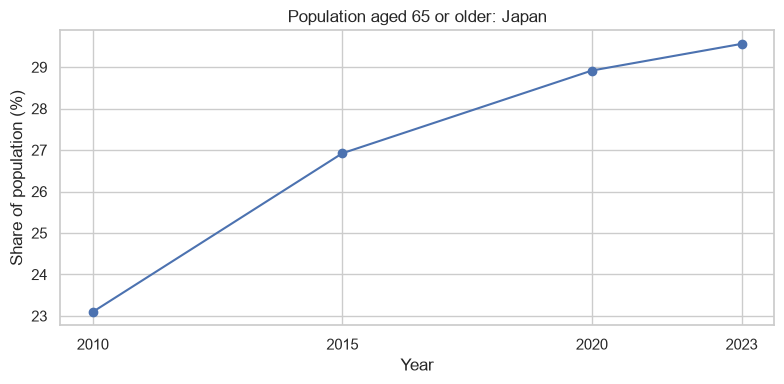

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(japan["year"], japan["share_65_plus"], marker="o")
ax.set(title="Population aged 65 or older: Japan", xlabel="Year", ylabel="Share of population (%)")
ax.set_xticks(japan["year"])
fig.tight_layout()
plt.show()

The markers represent the four observations for Japan. The connecting lines help us follow the series across the gaps between observation years.

## V-03 · A bar chart: compare countries in the same year

Sort `latest` by `share_65_plus`. Create a horizontal seaborn bar chart:
population share on x, country on y. Use one colour and `errorbar=None`.
Start the numerical axis at zero and label the year and percent unit.

Which country has the largest share among these eight countries?
Why is the same year important? Why would population counts answer a different question?

Useful tools: `sns.barplot(data=..., x=..., y=..., ax=...)`, `ax.set_xlim(left=0)`.

In [15]:
latest.head()

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
3,BRA,Brazil,2023,2.111407e+08,10.633631,75.848000,87.615971
7,CHN,China,2023,1.410710e+09,14.316077,77.953000,65.530145
11,DEU,Germany,2023,8.328727e+07,22.790044,81.041463,81.903437
15,IND,India,2023,1.438070e+09,6.921843,72.003000,35.067692
19,JPN,Japan,2023,1.245166e+08,29.561810,84.041220,92.082690


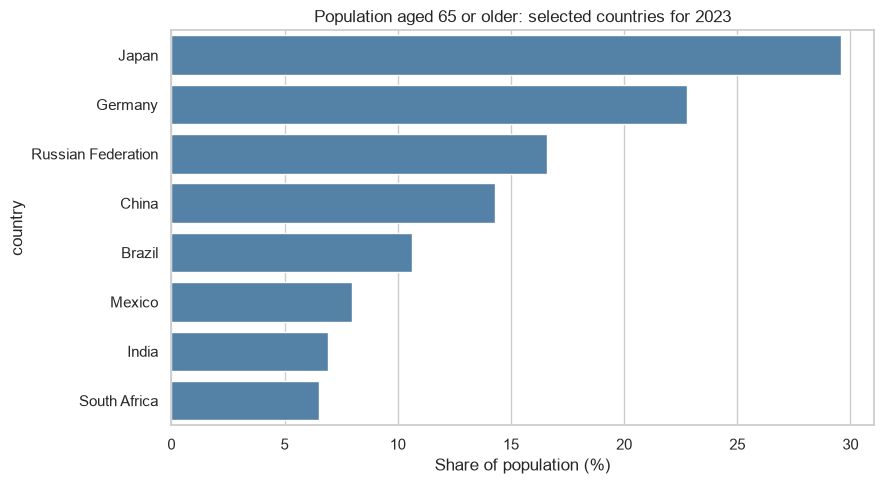

In [16]:
ordered = latest.sort_values("share_65_plus", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ordered, errorbar=None, color="steelblue", x="share_65_plus", y="country", ax=ax)
ax.set(title="Population aged 65 or older: selected countries for 2023", xlabel="Share of population (%)")
ax.set_xlim(left=0)
fig.tight_layout()
plt.show()

Japan has the largest share aged 65+ among these eight countries in 2023. Using one year gives each country the same reference period. A ranking by the number of older residents would also depend on population size.

## V-04 · A scatter plot: country-level association

Make a scatter plot of `share_65_plus` and `life_expectancy` for the 2023 table.
Use one point per country; give the axes clear units. Do not fit a regression line.
Describe the visible pattern, one limitation, and one possible omitted factor.

Would this chart show that changing the older population share causes a change
in an individual's lifespan? Explain why or why not.

Useful tool: `sns.scatterplot(data=..., x=..., y=..., s=..., ax=...)`.

In [17]:
latest

,country_code,country,year,population,share_65_plus,life_expectancy,urban_share
3,BRA,Brazil,2023,2.111407e+08,10.633631,75.848000,87.615971
7,CHN,China,2023,1.410710e+09,14.316077,77.953000,65.530145
11,DEU,Germany,2023,8.328727e+07,22.790044,81.041463,81.903437
15,IND,India,2023,1.438070e+09,6.921843,72.003000,35.067692
19,JPN,Japan,2023,1.245166e+08,29.561810,84.041220,92.082690
23,MEX,Mexico,2023,1.297398e+08,7.986646,75.069000,79.473494
27,RUS,Russian Federation,2023,1.438261e+08,16.604643,73.254634,74.980505
31,ZAF,South Africa,2023,6.321238e+07,6.515094,66.139000,63.582371


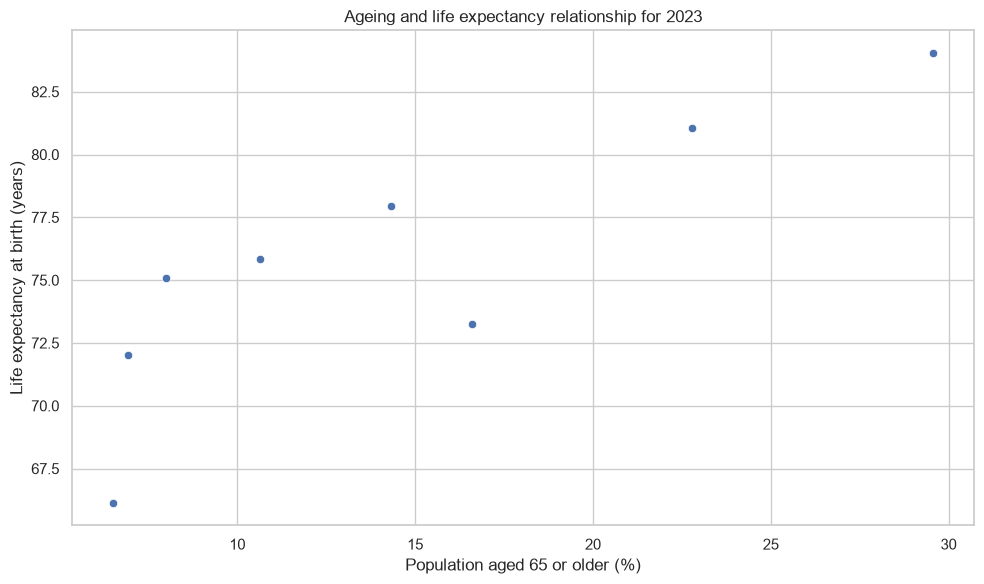

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=latest, x="share_65_plus", y="life_expectancy", ax=ax)
ax.set(title="Ageing and life expectancy relationship for 2023", xlabel="Population aged 65 or older (%)", ylabel="Life expectancy at birth (years)")
fig.tight_layout()
plt.show()

Countries with a larger older population share generally have higher life expectancy in this snapshot. Health care and other differences between countries could affect this pattern. Each point summarises an entire country, so the plot alone cannot identify a causal effect on individual lifespan.

## V-05 · Export a figure that can stand on its own

Save the scatter plot as `outputs/ageing_scatter.png` at 150 dpi with tight borders.
Create the output folder if needed. Add a Markdown caption with the source,
year, unit of observation, and one limitation.

Use the existing `fig` from V-04. Save before creating another figure.
Useful tools: `Path(...).mkdir(exist_ok=True)`, `fig.savefig(..., dpi=150, bbox_inches="tight")`.

In [19]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

fig.savefig("outputs/ageing_scatter.png", dpi=150, bbox_inches="tight")

**Figure caption.** World Bank World Development Indicators, 2023. Each dot shows the share aged 65+ (%) and life expectancy at birth (years) for one of eight selected countries. The selection limits how far we can generalise the pattern.